## Import Libraries

In [4]:
import netrc
import requests
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pathlib import Path
from siphon.catalog import TDSCatalog
from siphon.http_util import session_manager


## Load dataset

In [5]:
# SWOT passes available in the region 
SWOT_passes = pd.read_csv('selected_passes.csv', sep=';',
                          parse_dates=['First date', 'Last date'])
SWOT_passes

,Cycle number,Pass number,First date,Last date
0,55,320,2026-09-01 07:53:10,2026-09-01 07:53:55
1,55,335,2026-09-01 21:08:30,2026-09-01 21:08:42
2,55,348,2026-09-02 07:53:41,2026-09-02 07:54:26
3,55,363,2026-09-02 21:09:02,2026-09-02 21:09:46
4,56,14,2026-09-11 06:15:26,2026-09-11 06:15:37
5,56,42,2026-09-12 06:15:57,2026-09-12 06:16:42
6,56,57,2026-09-12 19:31:18,2026-09-12 19:32:02
7,56,85,2026-09-13 19:31:49,2026-09-13 19:32:33
8,56,320,2026-09-22 04:38:14,2026-09-22 04:38:58
9,56,335,2026-09-22 17:53:34,2026-09-22 17:53:46


In [6]:
# Credentials from ~/.netrc
HOST = 'tds-odatis.aviso.altimetry.fr'   # must match the "machine" entry in .netrc
user, _, password = netrc.netrc().authenticators(HOST)
session_manager.set_session_options(auth=(user, password))

# Catalog URL up to "forward/" -> adjust to your server
BASE = (f'https://{HOST}/thredds/catalog/'
        'dataset-l3-swot-karin-nadir-validated/'
        'l3_lr_ssh/v3_0/Expert/forward')

out_dir = Path('swot_data')
out_dir.mkdir(exist_ok=True)


catalogs = {}   # one catalog per cycle, to avoid requesting it for every pass
swaths = {}

for _, row in SWOT_passes.iterrows():
    cycle, pass_ = int(row['Cycle number']), int(row['Pass number'])

    if cycle not in catalogs:
        catalogs[cycle] = TDSCatalog(f'{BASE}/cycle_{cycle:03d}/catalog.xml')

    # Find the file matching this cycle/pass
    tag = f'_{cycle:03d}_{pass_:03d}_'
    names = [n for n in catalogs[cycle].datasets if tag in n]
    if not names:
        print(f'No file found for cycle {cycle:03d}, pass {pass_:03d}')
        continue

    # Download only if not already cached locally
    name = sorted(names)[-1]
    local = out_dir / name
    if not local.exists():
        url = catalogs[cycle].datasets[name].access_urls['HTTPServer']
        r = requests.get(url, auth=(user, password))
        r.raise_for_status()   # stop here on 401/404/... instead of saving garbage
        local.write_bytes(r.content)

    ds = xr.open_dataset(local)

    # Along-track crop to the time window of interest
    t = ds['time'].load()
    mask = (t >= row['First date']) & (t <= row['Last date'])
    swaths[(cycle, pass_)] = ds.isel(num_lines=mask.values)

No file found for cycle 055, pass 335


In [7]:
# Longitude correction for the passes that cross the Greenwich meridian
s = ds.isel(num_lines=mask.values)
# Wrap longitude to -180..180 (some passes cross the Greenwich meridian)
s = s.assign_coords(longitude=((s.longitude + 180) % 360) - 180)
swaths[(cycle, pass_)] = s

## SWOT Swaths Plot

In [8]:
# Define plotting function for swath with ADT and geostrophic velocity arrows on a given axis
def plot_swath(s, ax, vmax, offset, step=5, labels=('bottom', 'left')):
    """ADT map with absolute geostrophic velocity arrows on a given axis."""
    adt = (s['ssha_filtered'] + s['mdt']).values - offset
    lon = ((s['longitude'].values + 180) % 360) - 180   # wrap to -180..180
    lat = s['latitude'].values

    pcm = ax.pcolormesh(lon, lat, adt, cmap='RdBu_r', vmin=-vmax, vmax=vmax,
                        transform=ccrs.PlateCarree())

    # Subsample arrows to keep the plot readable
    sl = (slice(None, None, step), slice(None, None, step))
    q = ax.quiver(lon[sl], lat[sl],
                  s['ugos_filtered'].values[sl], s['vgos_filtered'].values[sl],
                  scale=8, width=0.004, transform=ccrs.PlateCarree())

    ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor='0.85', zorder=2)
    ax.coastlines(resolution='10m', zorder=3)
    ax.gridlines(draw_labels=list(labels), linewidth=0.3)
    return pcm, q

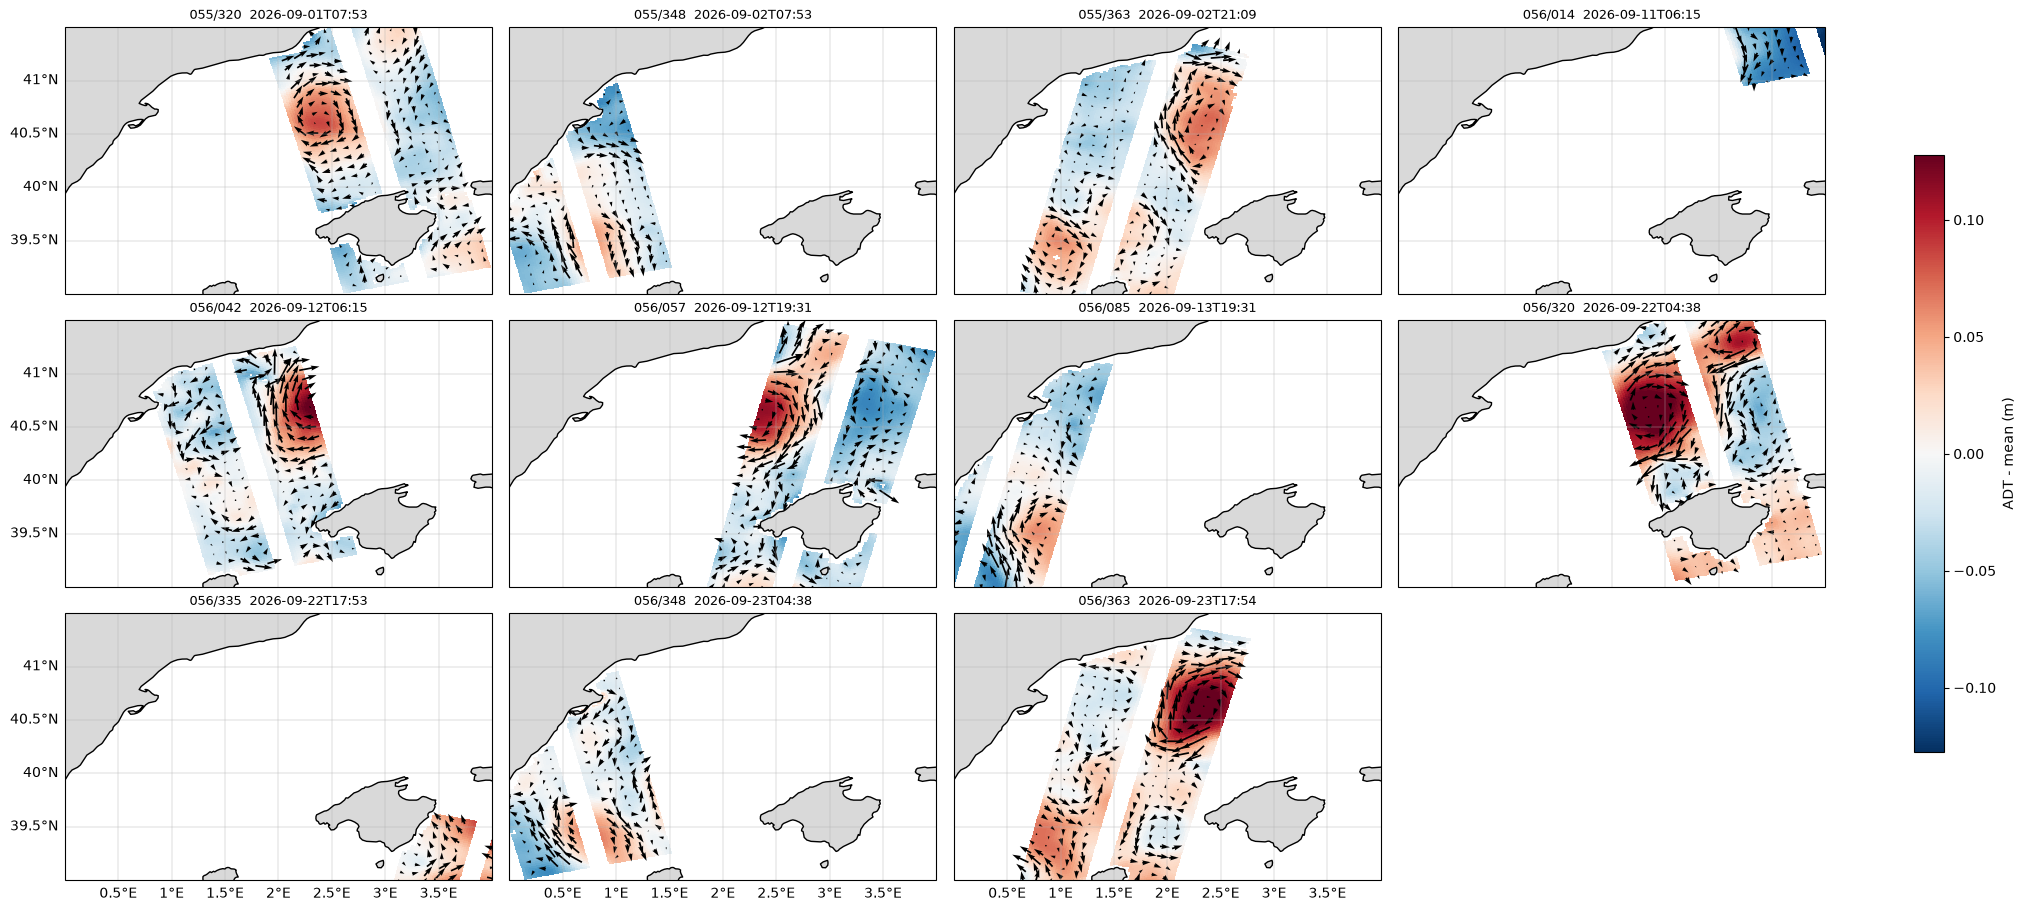

In [15]:
EXTENT = [0, 4, 39, 41.5]   # lon_min, lon_max, lat_min, lat_max

# Common reference and colour range for all passes
all_adt = np.concatenate([(s['ssha_filtered'] + s['mdt']).values.ravel()
                          for s in swaths.values()])
offset = np.nanmean(all_adt)
vmax = np.nanpercentile(np.abs(all_adt - offset), 98)

n = len(swaths)
ncols = int(np.ceil(np.sqrt(n)))
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 9), layout='constrained',
                         subplot_kw={'projection': ccrs.PlateCarree()})

for i, (ax, ((cycle, pass_), s)) in enumerate(zip(axes.flat, swaths.items())):
    # Tick labels only on the left column and bottom row
    labels = []
    if i // ncols == nrows - 1:
        labels.append('bottom')
    if i % ncols == 0:
        labels.append('left')

    pcm, q = plot_swath(s, ax, vmax, offset, labels=labels)
    ax.set_title(f'{cycle:03d}/{pass_:03d}  {str(s.time.values[0])[:16]}',
                 fontsize=9)

# Remove empty panels
for ax_empty in axes.flat[len(swaths):]:
    ax_empty.remove()

fig.colorbar(pcm, ax=axes.flat[:len(swaths)], label='ADT - mean (m)', shrink=0.7)
ax.quiverkey(q, 0.9, 1.03, 0.5, '0.5 m/s', labelpos='W', coordinates='figure')

fig.savefig('swot_all_passes.png', dpi=300, bbox_inches='tight')